# ML Lab 4
## Name: Krish Potanwa
## Class And Batch: C2-B1-12

In [115]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

In [116]:
df = pd.read_csv('winequality-red.csv')

In [117]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [118]:
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [119]:
df.shape

(1599, 12)

In [120]:
df.info

<bound method DataFrame.info of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.067

In [121]:
df.describe

<bound method NDFrame.describe of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.0

In [122]:
df.isnull().sum

<bound method DataFrame.sum of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0             False             False        False           False      False   
1             False             False        False           False      False   
2             False             False        False           False      False   
3             False             False        False           False      False   
4             False             False        False           False      False   
...             ...               ...          ...             ...        ...   
1594          False             False        False           False      False   
1595          False             False        False           False      False   
1596          False             False        False           False      False   
1597          False             False        False           False      False   
1598          False             False        False           False      False 

In [123]:
df.duplicated().sum()

np.int64(240)

In [124]:
df = df.drop_duplicates()

In [125]:
df.duplicated().sum()

np.int64(0)

In [126]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

# 1 Univariant Analysis

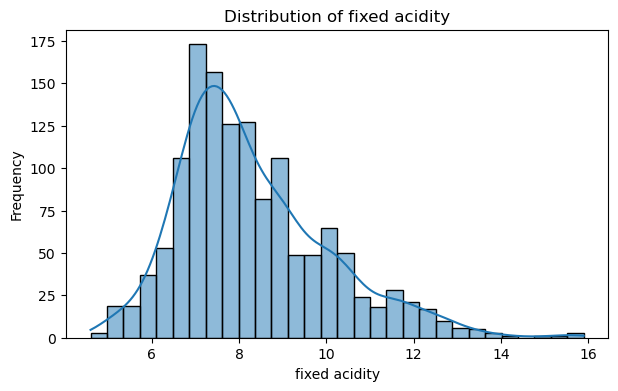

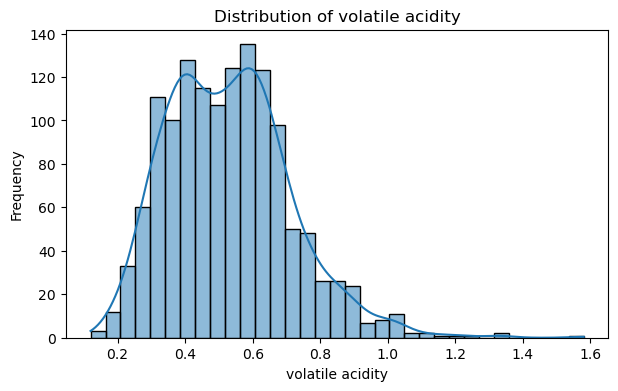

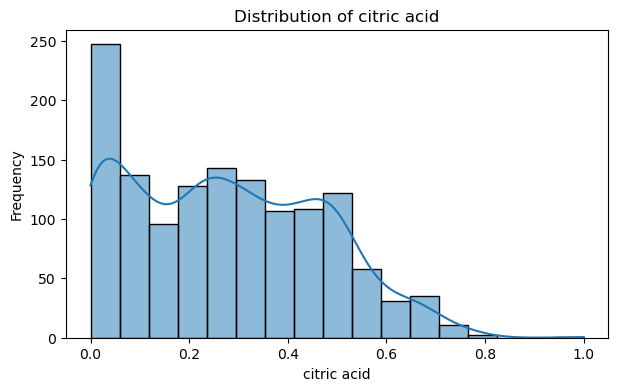

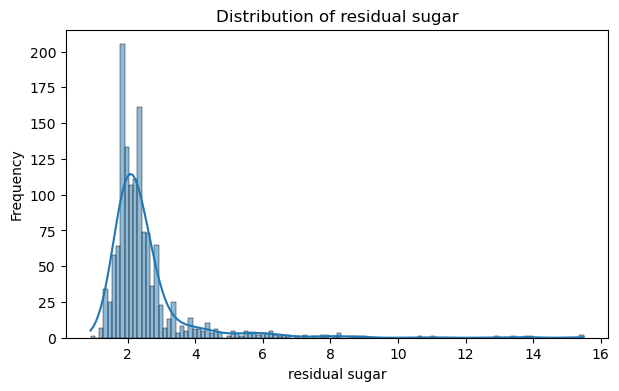

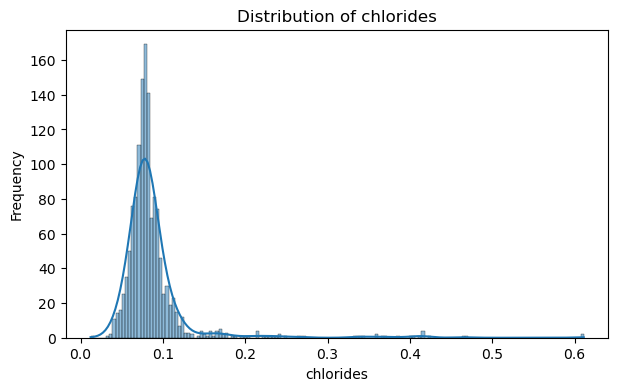

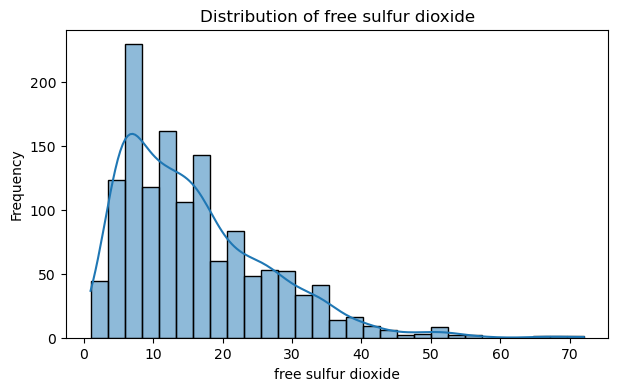

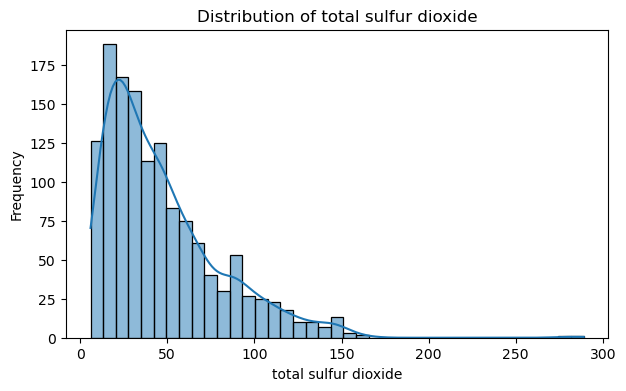

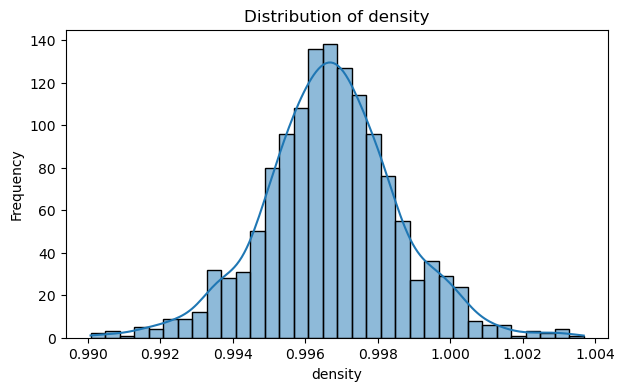

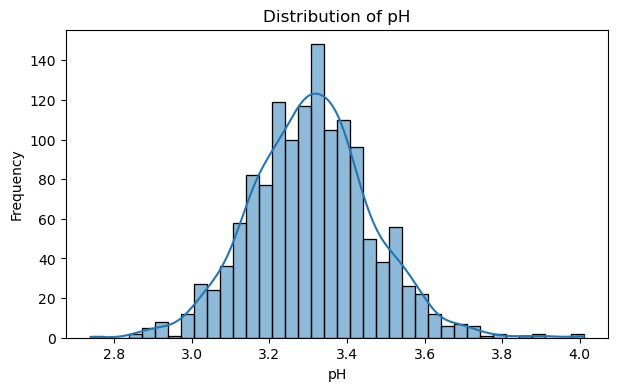

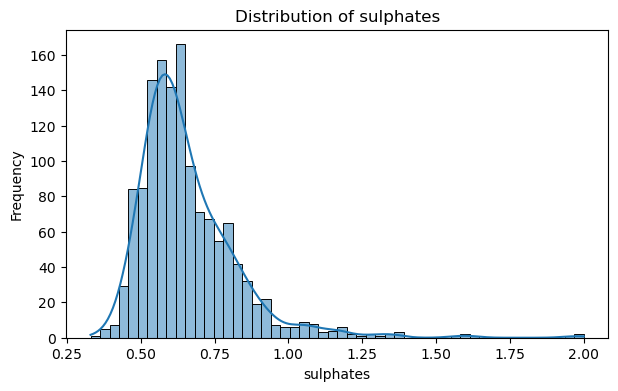

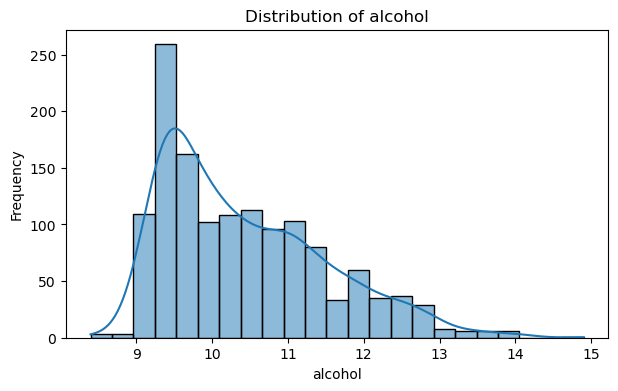

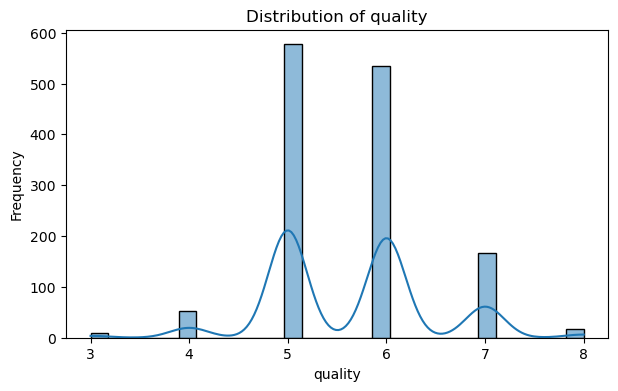

In [127]:
#Histogram + KDE
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df.columns

for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

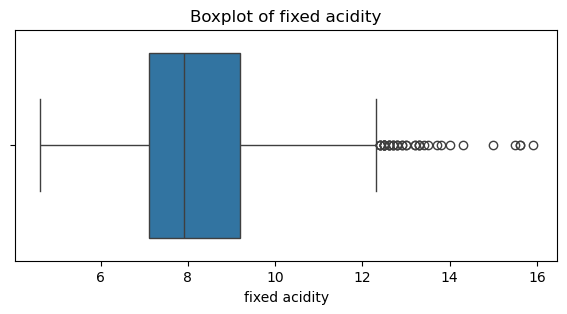

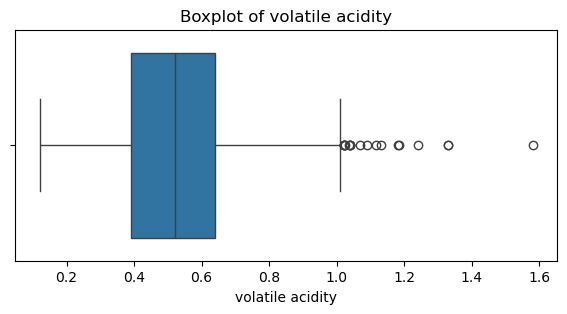

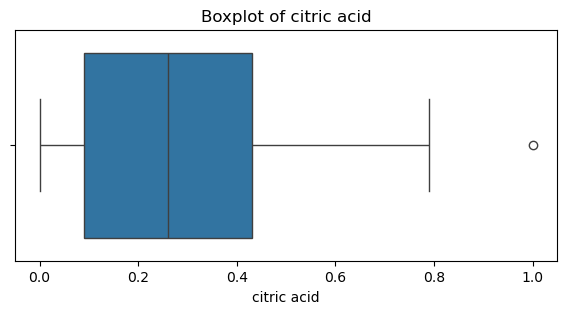

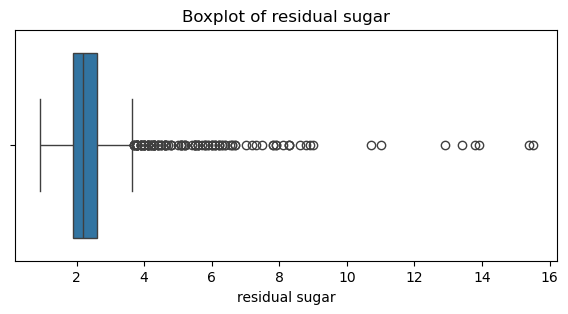

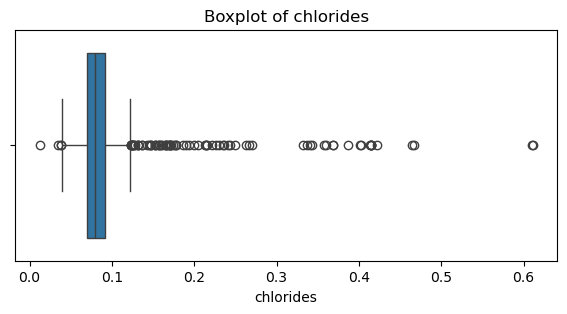

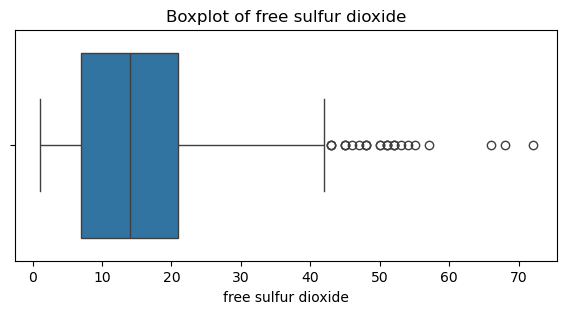

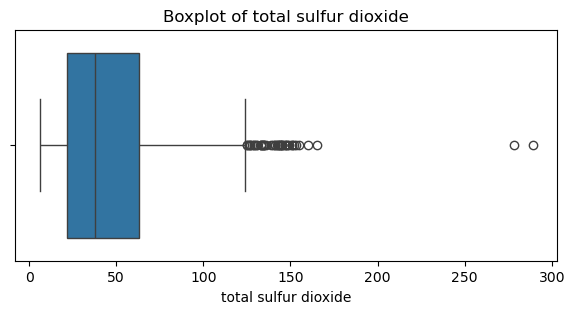

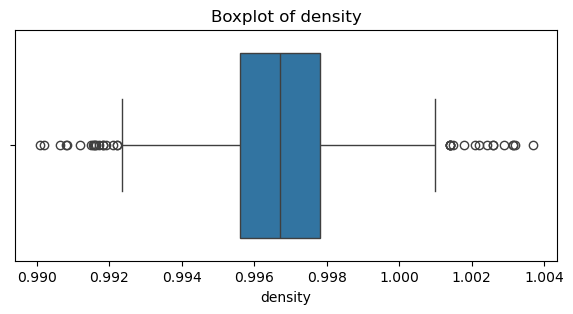

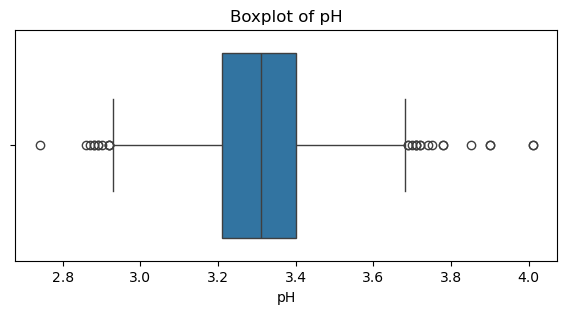

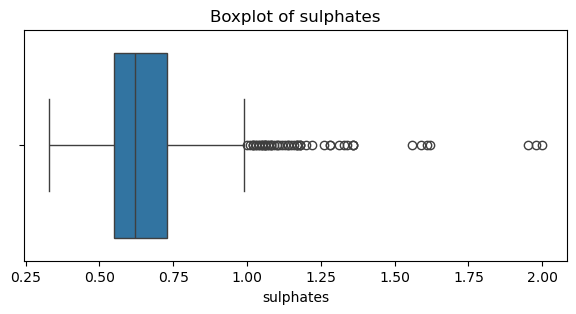

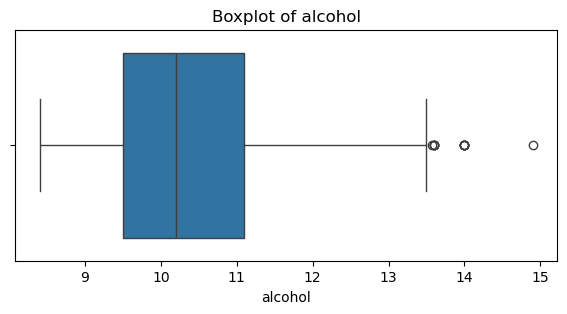

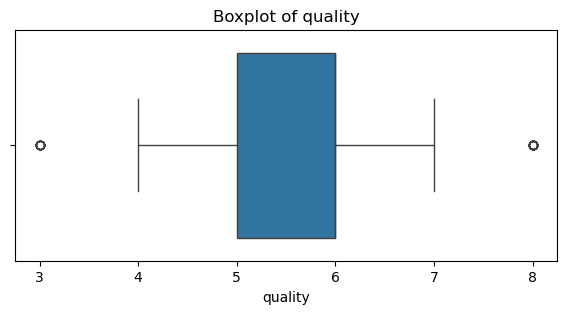

In [128]:
# Boxplot - Outlier ANalysis
for col in numeric_cols:
    plt.figure(figsize=(7,3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

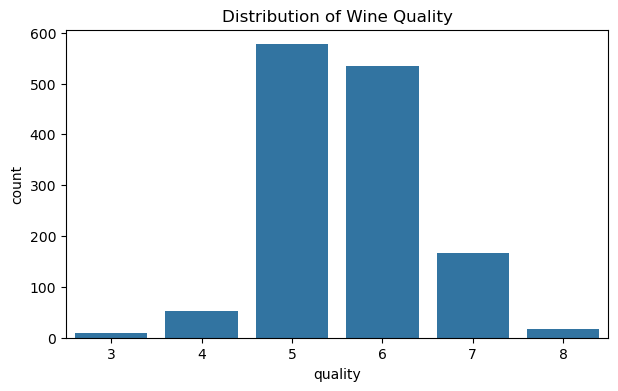

In [129]:
plt.figure(figsize=(7,4))
sns.countplot(x='quality', data=df)
plt.title('Distribution of Wine Quality')
plt.show()

In [130]:
# Q1 = df[numeric_cols].quantile(0.25)
# Q3 = df[numeric_cols].quantile(0.75)

# IQR = Q3 - Q1

# df = df[~((df[numeric_cols] < (Q1 - 1.5 * IQR)) |
#           (df[numeric_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

# print("Outliers removed successfully!")

In [131]:
df['quality'].value_counts().sort_index()

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

# 2. Bivariate Analysis

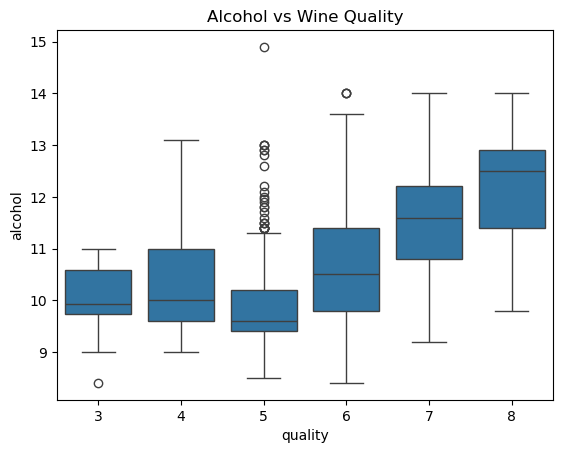

In [132]:
# Alcohol vs Quality
sns.boxplot(x='quality', y='alcohol', data=df)
plt.title('Alcohol vs Wine Quality')
plt.show()

In [133]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


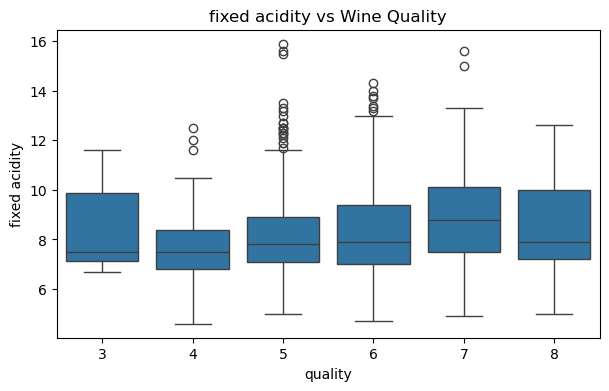

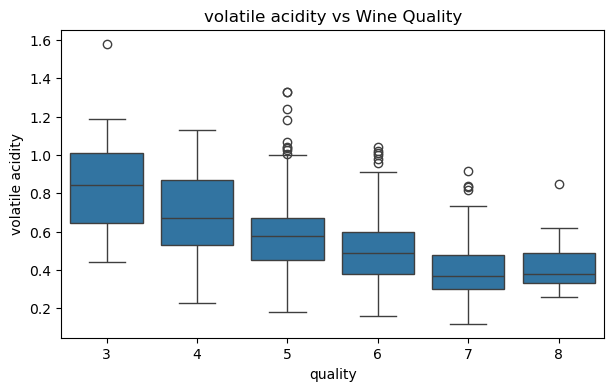

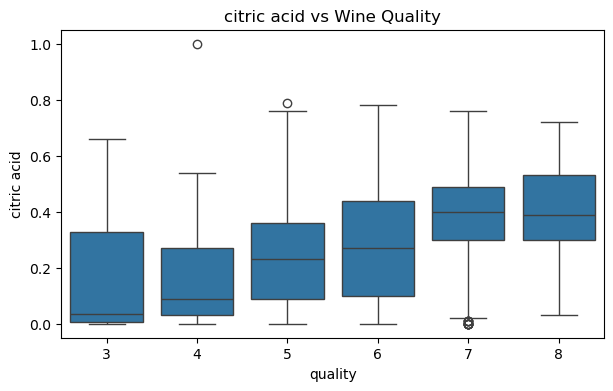

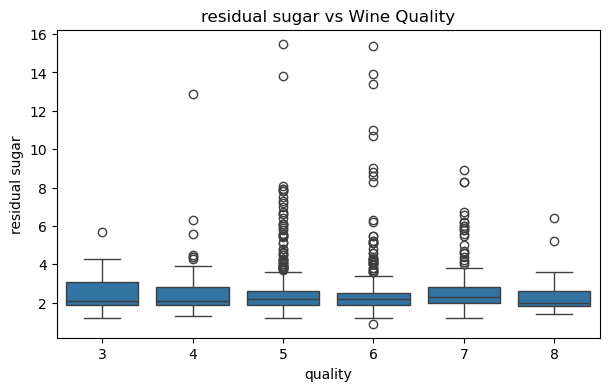

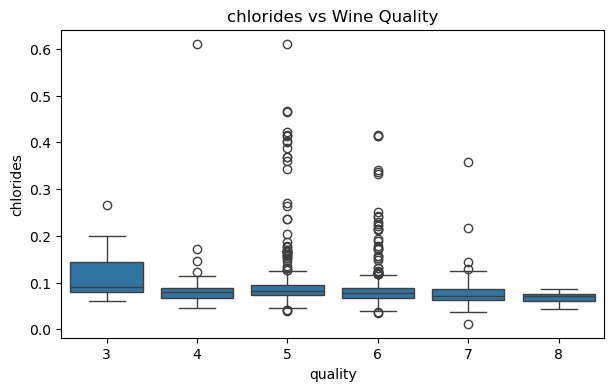

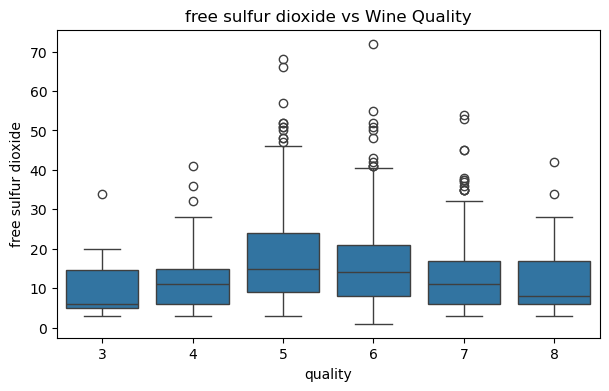

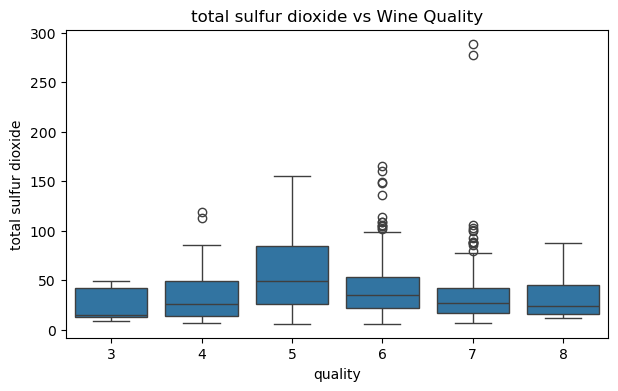

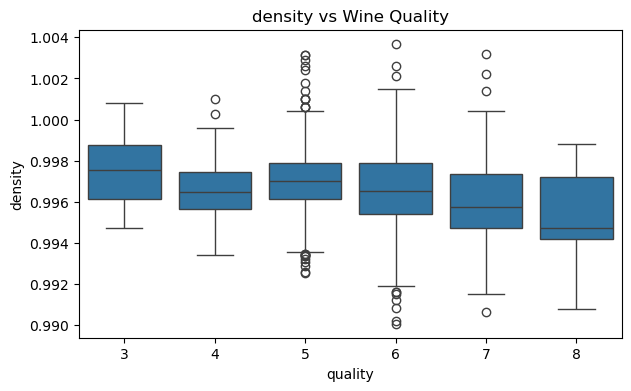

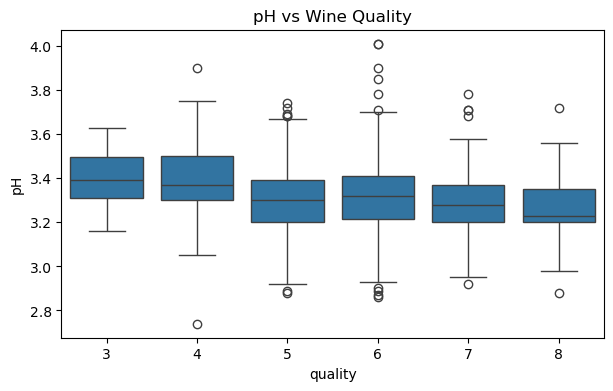

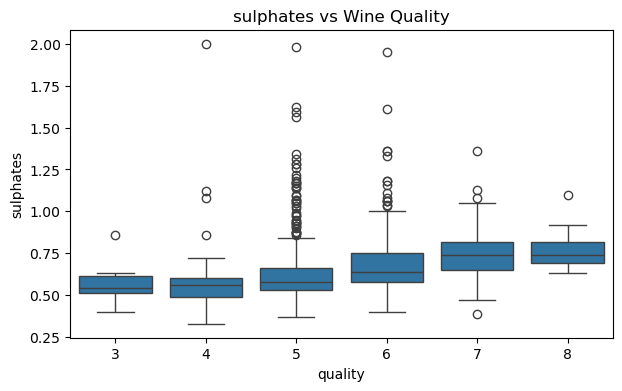

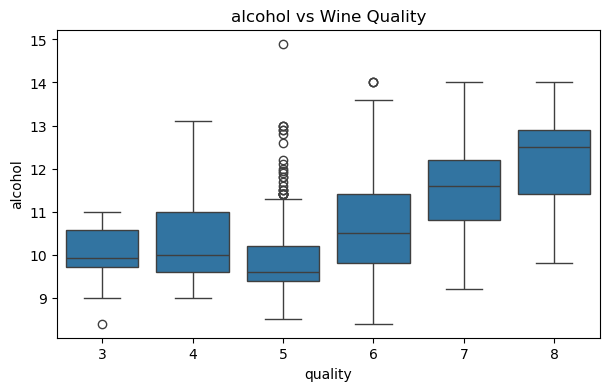

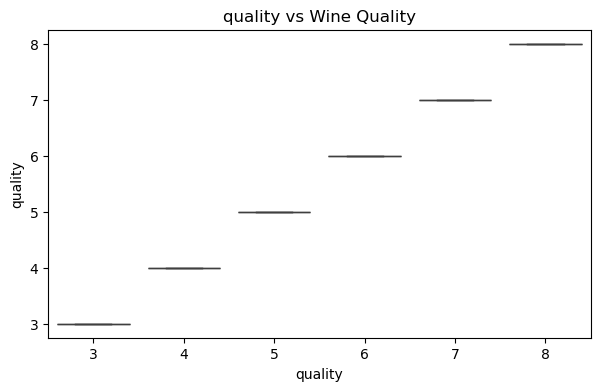

In [134]:
features = ['fixed acidity','volatile acidity','citric acid','residual sugar','chlorides','free sulfur dioxide','total sulfur dioxide','density','pH','sulphates','alcohol', 'quality']

for col in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x='quality' , y =col, data=df)
    plt.title(f'{col} vs Wine Quality')
    plt.show()

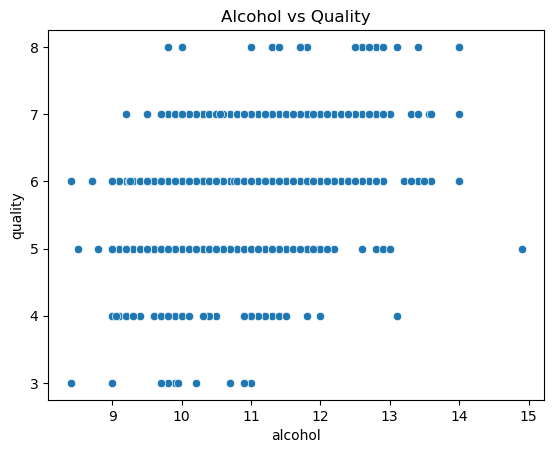

In [135]:
#Scatter PLot
sns.scatterplot(x='alcohol', y='quality', data=df)
plt.title('Alcohol vs Quality')
plt.show()

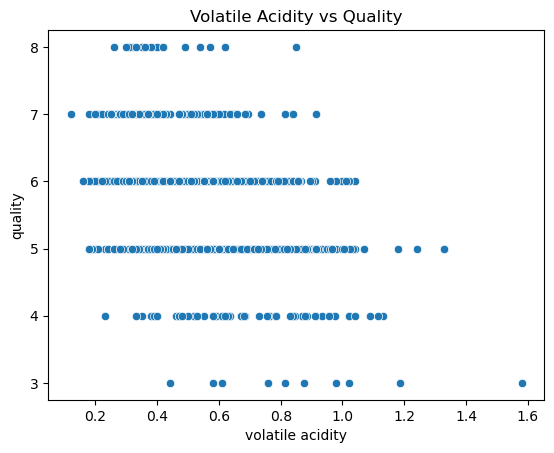

In [136]:
sns.scatterplot(x='volatile acidity', y='quality', data=df)
plt.title('Volatile Acidity vs Quality')
plt.show()

# 3. Multivariate Analysis

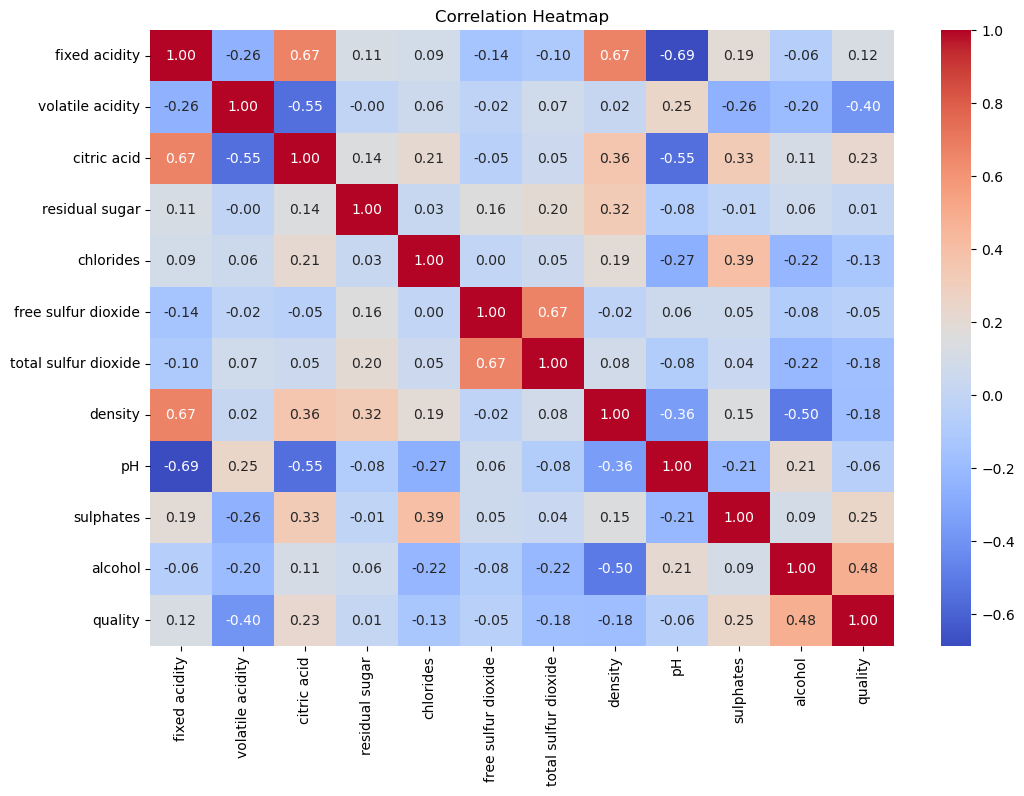

In [137]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

corr = df.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

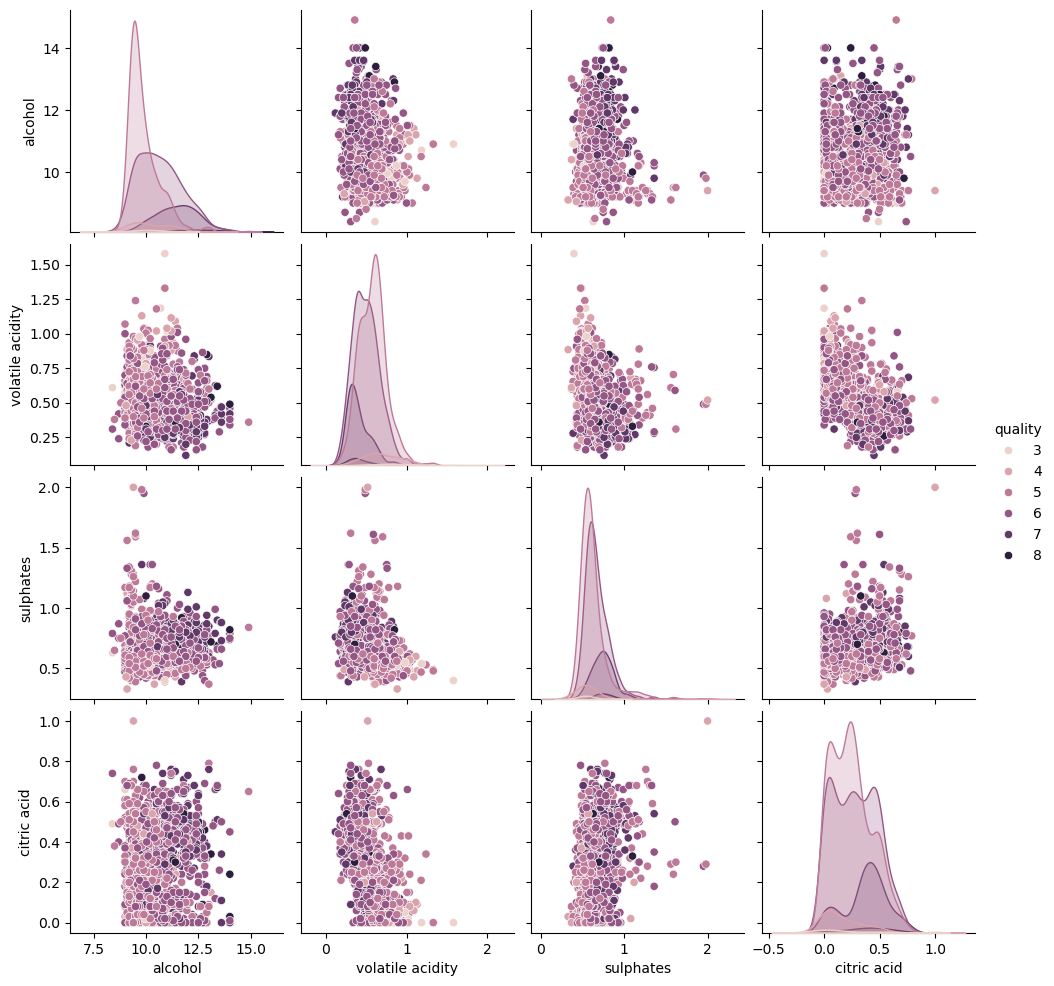

In [138]:
#Pair Plot
selected = ['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'quality']

sns.pairplot(df[selected],hue='quality')

plt.show()

In [139]:
#Multivariate Analysis Using Quality Groups
df['quality_groups'] = pd.cut(
    df['quality'],
    bins=[0, 5, 6, 10],
    labels=['Low', 'Medium', 'High']
)

/var/folders/x1/00_0s8_s0pq4pbfqd5g6nk5h0000gn/T/ipykernel_60702/1522358151.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['quality_groups'] = pd.cut(


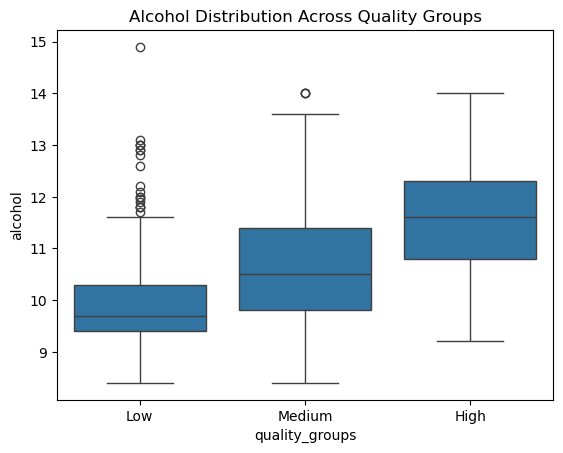

In [140]:
sns.boxplot(
    x='quality_groups',
    y='alcohol',
    data=df
)

plt.title('Alcohol Distribution Across Quality Groups')
plt.show()

In [141]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [142]:
X = df.drop('quality',axis=1)
y = df['quality']

In [143]:
print("X shape:", X.shape)
print("y Shape:", y.shape)

X shape: (1359, 12)
y Shape: (1359,)


In [144]:
print(y.value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


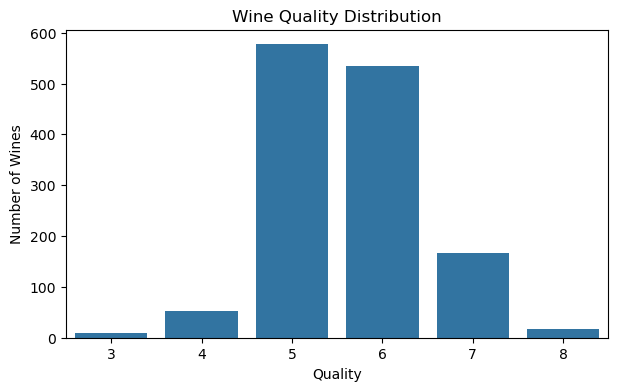

In [145]:
plt.figure(figsize=(7,4))

sns.countplot(x=y)

plt.title("Wine Quality Distribution")
plt.xlabel("Quality")
plt.ylabel("Number of Wines")
plt.show()

In [146]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state = 42, stratify = y)

In [147]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1087, 12)
X_test: (272, 12)
y_train: (1087,)
y_test: (272,)


In [148]:
criterion = 'entropy'

In [149]:
dt_model = DecisionTreeClassifier(
    criterion = 'entropy',
    random_state = 42,
)

In [150]:
print(X.select_dtypes(exclude='number').columns)

Index(['quality_groups'], dtype='object')


In [151]:
y = df['quality']

In [152]:
X = df.drop(columns = ['quality', 'quality_groups'], errors='ignore')

In [153]:
print(X.columns)
print(X.dtypes)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='object')
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object


In [154]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state = 42, stratify = y)

In [155]:
df['quality_groups'] = pd.cut(
    df['quality'],
    bins=[0, 5, 6, 10],
    labels=['Low', 'Medium', 'High']
)

/var/folders/x1/00_0s8_s0pq4pbfqd5g6nk5h0000gn/T/ipykernel_60702/3986903225.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['quality_groups'] = pd.cut(


In [156]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

dt_model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [157]:
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [158]:
y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

In [159]:
train_accuracy = accuracy_score(y_train, y_train_pred)
print("Training Accuracy:", train_accuracy)

Training Accuracy: 1.0


In [160]:
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.4963235294117647


In [161]:
print("Precision:", precision_score(y_test, y_test_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_test_pred, average='weighted'))
print("F1 score:", f1_score(y_test, y_test_pred, average='weighted'))

Precision: 0.49434982217769985
Recall: 0.4963235294117647
F1 score: 0.4951045941835992


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [162]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.64      0.62      0.63       116
           6       0.47      0.50      0.48       107
           7       0.29      0.30      0.30        33
           8       0.00      0.00      0.00         3

    accuracy                           0.50       272
   macro avg       0.23      0.24      0.24       272
weighted avg       0.49      0.50      0.50       272



/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


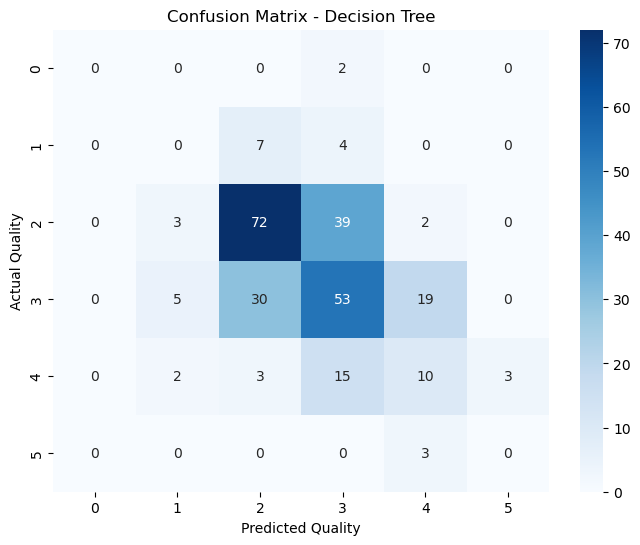

In [163]:
#Confusion Matrix

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize = (8, 6))

sns.heatmap( cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted Quality')
plt.ylabel('Actual Quality')
plt.title('Confusion Matrix - Decision Tree')

plt.show()

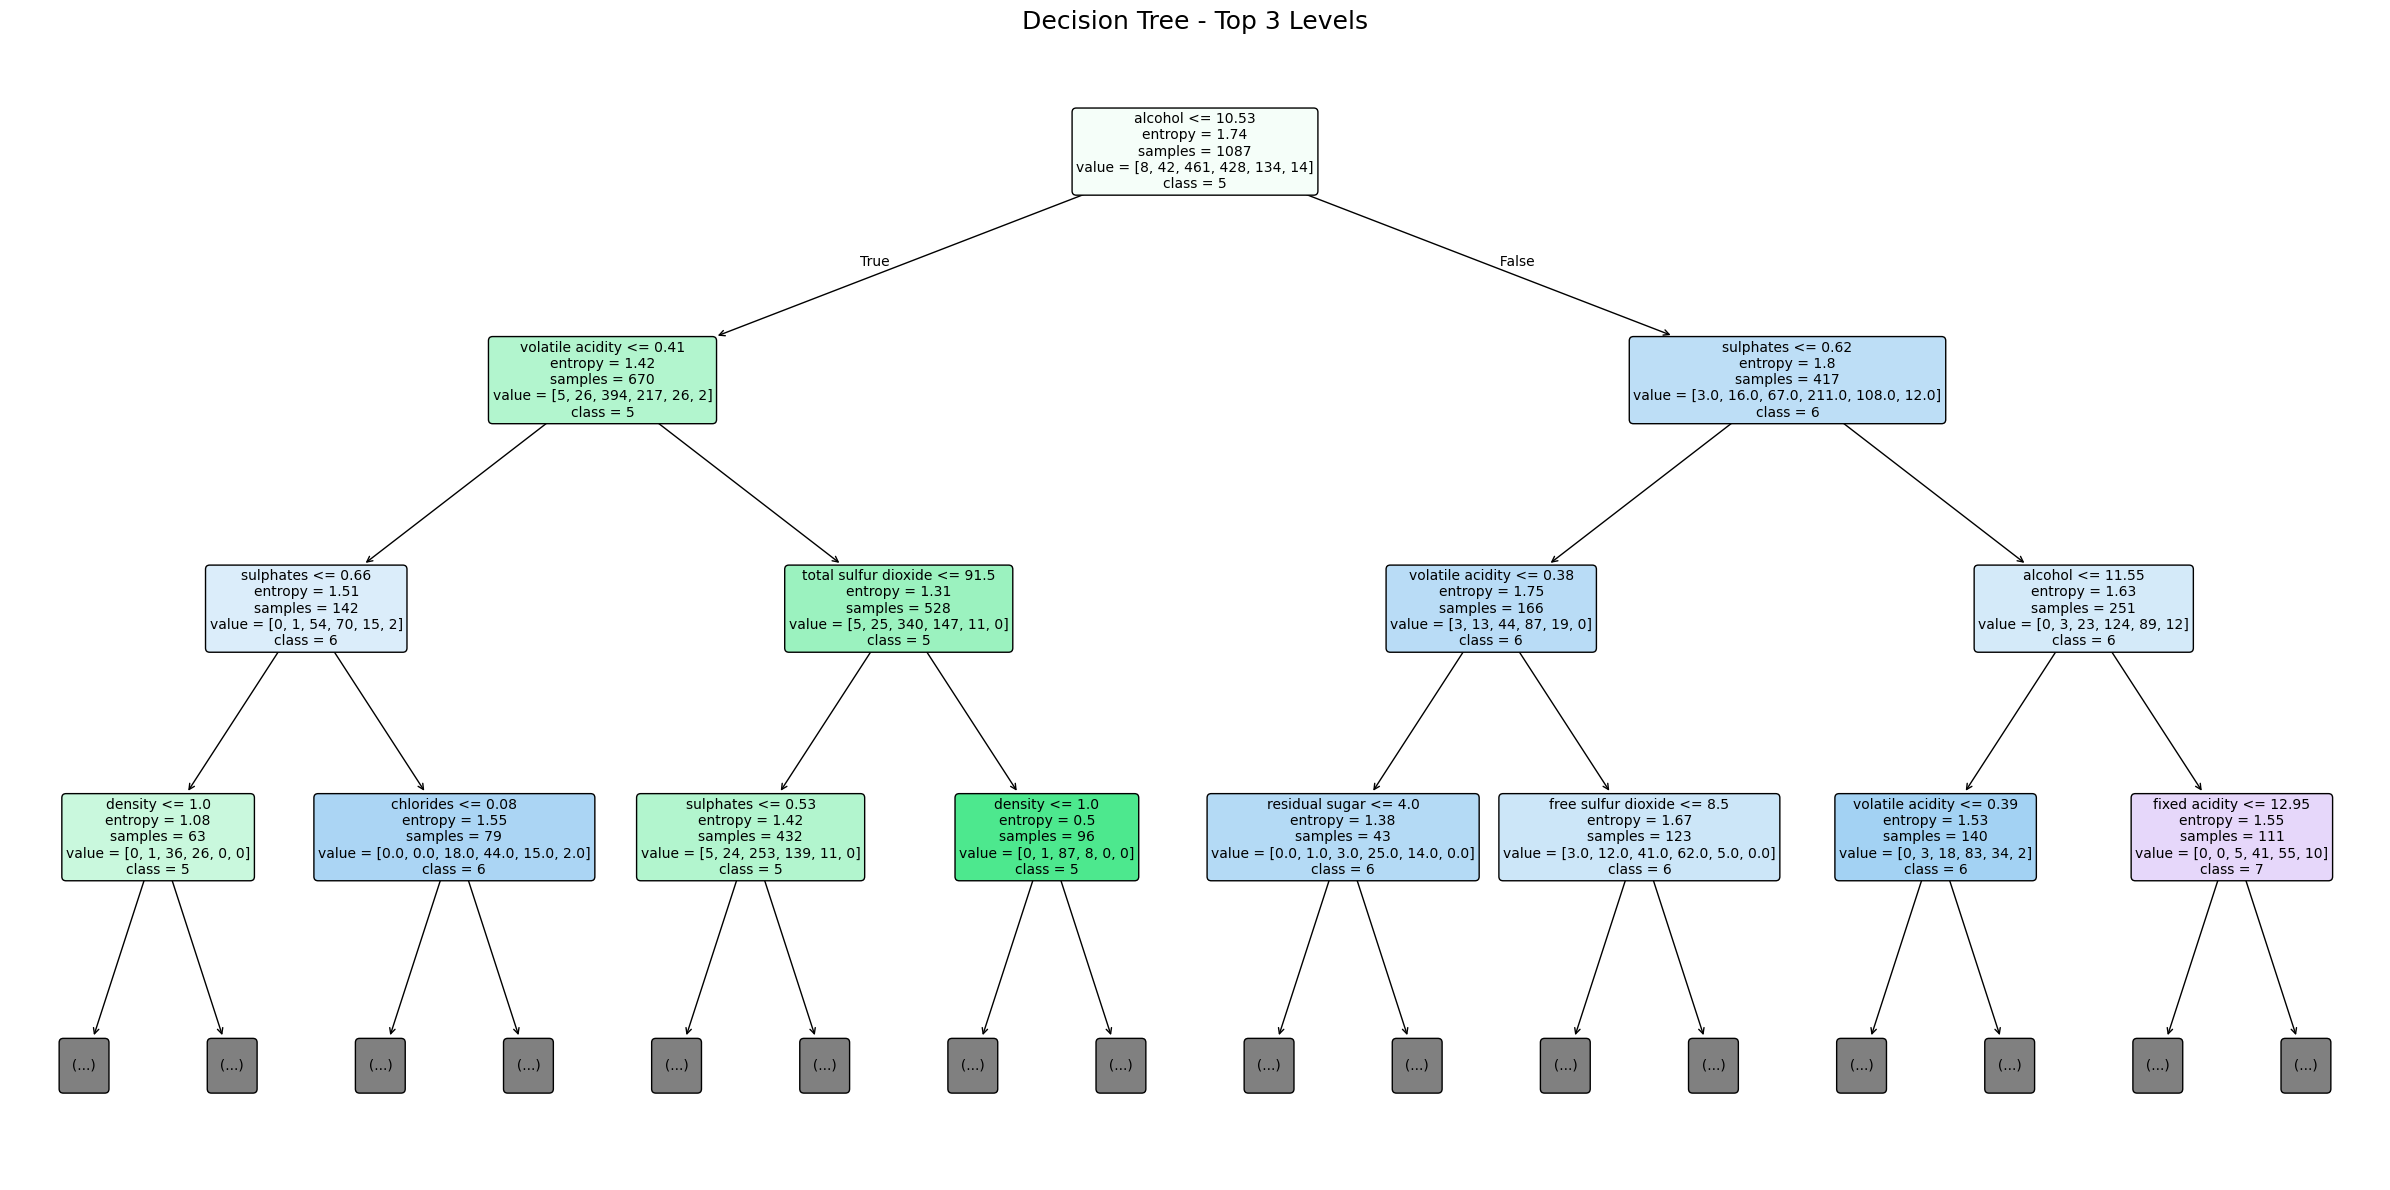

In [164]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24,12))

plot_tree(dt_model,
          feature_names = X.columns, 
          class_names = [str(c) for c in sorted(y.unique())],
          filled = True, 
          rounded = True, 
          impurity = True, 
          precision = 2, 
          fontsize=10, 
          max_depth=3)
plt.title("Decision Tree - Top 3 Levels", fontsize = 18)
plt.tight_layout()
plt.show()

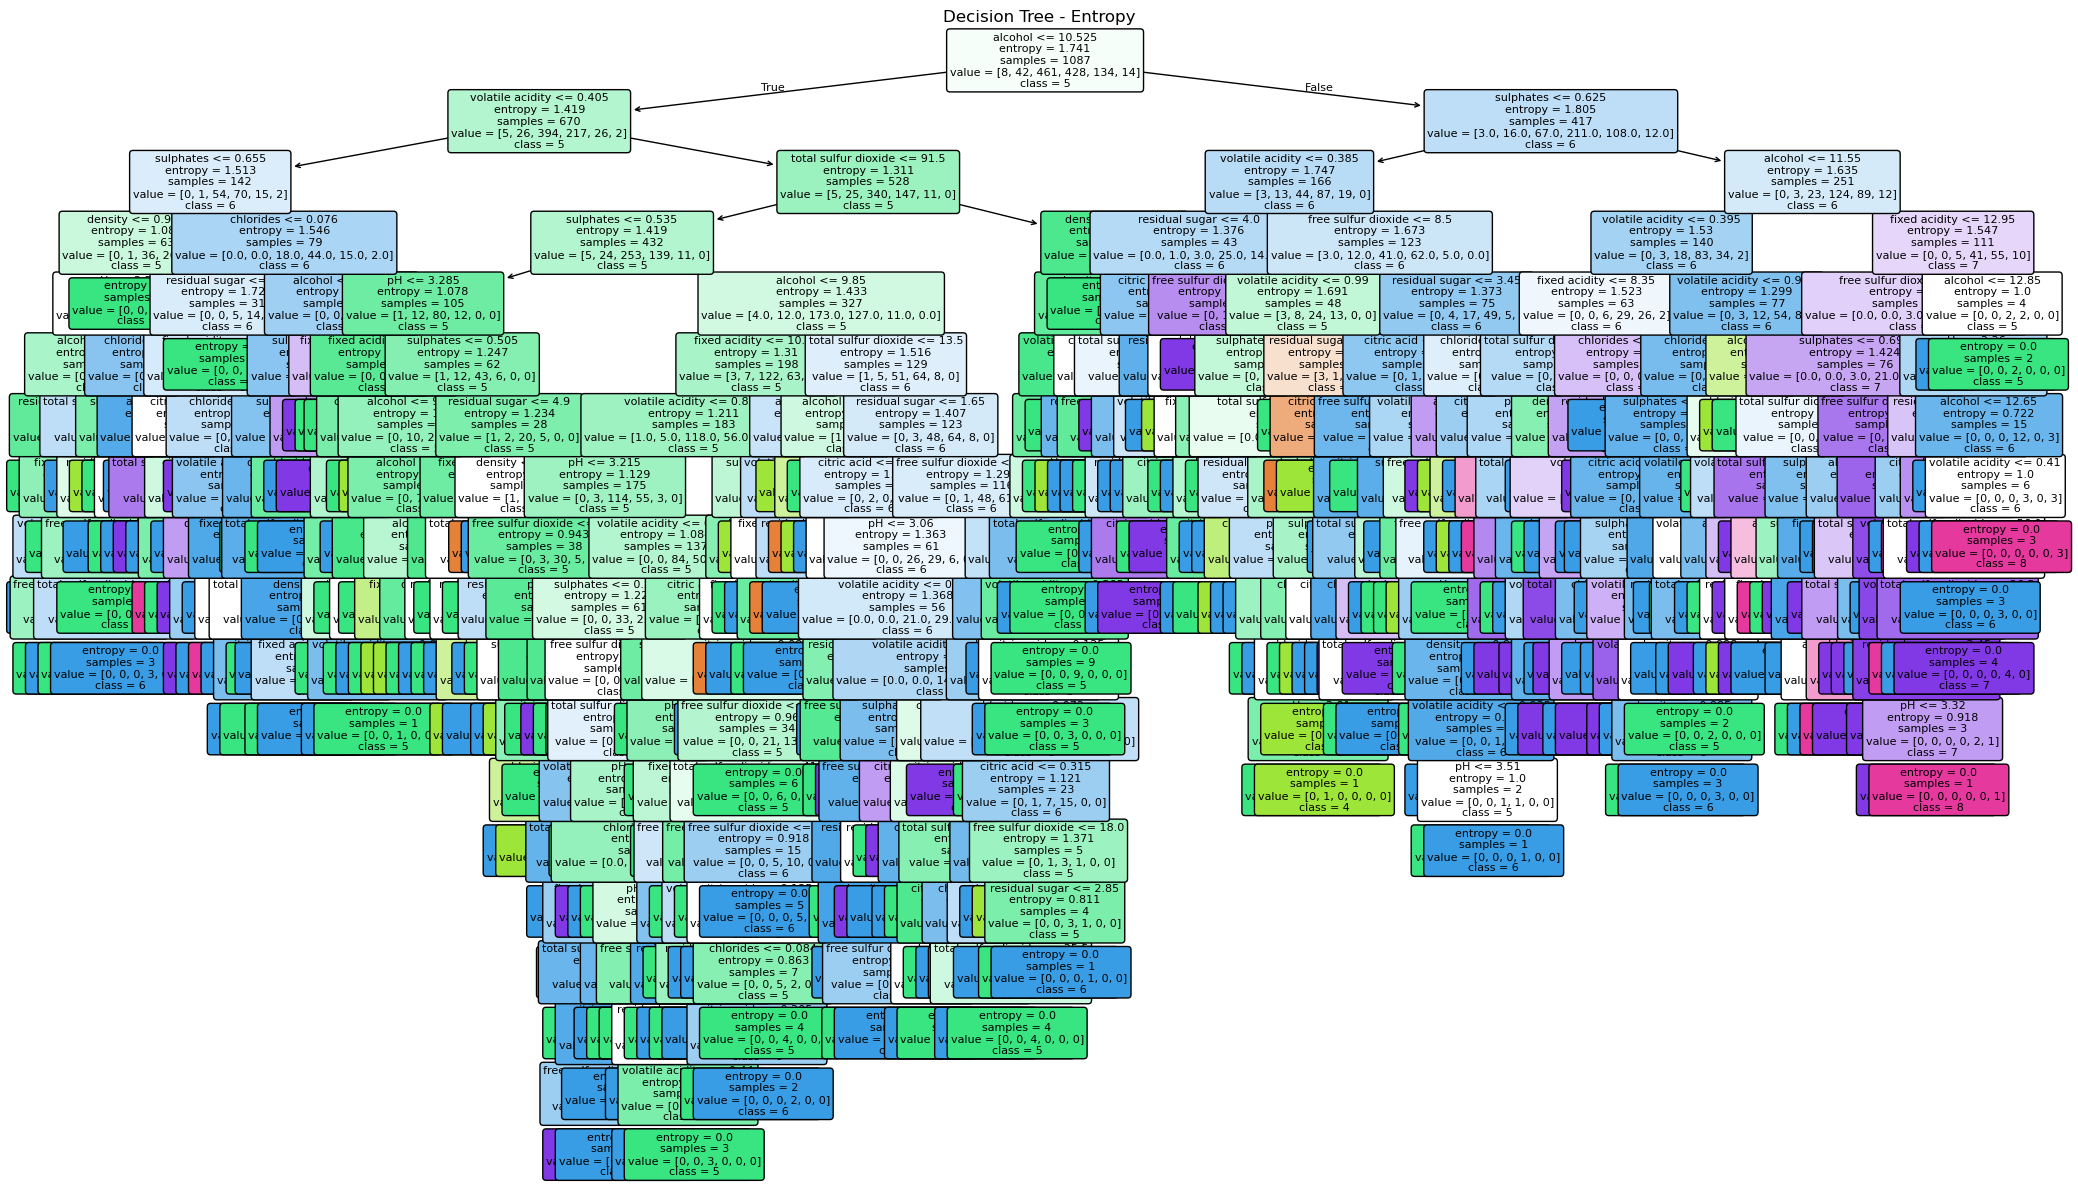

In [165]:
plt.figure(figsize=(25, 15))

plot_tree(
    dt_model,
    feature_names = X.columns,
    class_names = [str(c) for c in sorted(y.unique())],
    filled = True,
    rounded = True,
    fontsize = 8
)

plt.title("Decision Tree - Entropy")
plt.show()


Overall


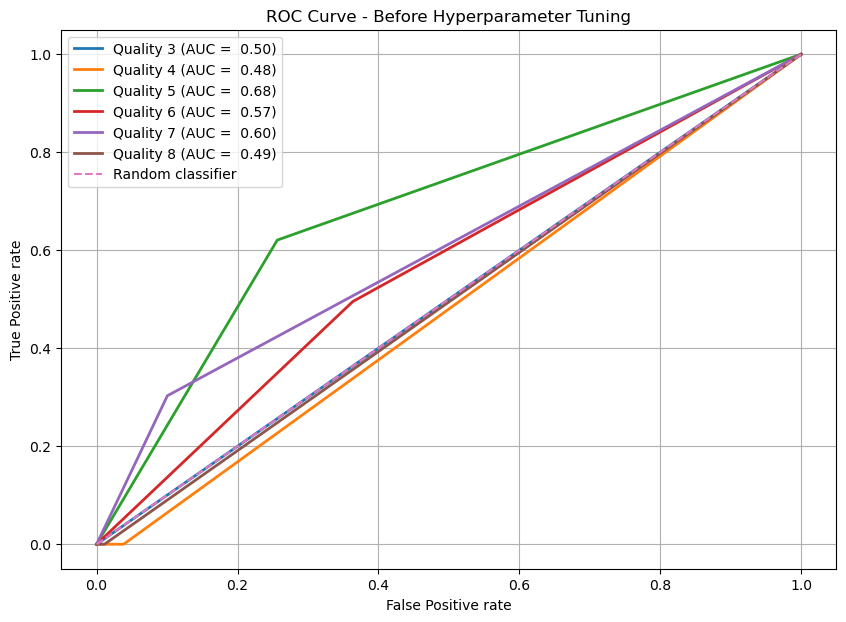

In [166]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score



#Get Unique classes
classes = sorted(y_test.unique())

#convert y_test to binary format
y_test_bin = label_binarize(y_test, classes = classes)


#Get probability predicitions
y_score = dt_model.predict_proba(X_test)

#plot ROC curve
plt.figure(figsize = (10,7))

for i, class_label in enumerate(classes):

    fpr,tpr,thresholds = roc_curve(
        y_test_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot( fpr,tpr,linewidth = 2, label = f'Quality {class_label} (AUC = {roc_auc: .2f})')

plt.plot([0,1],[0,1],linestyle='--',label='Random classifier')
plt.xlabel('False Positive rate')
plt.ylabel('True Positive rate')
plt.title('ROC Curve - Before Hyperparameter Tuning')

plt.legend()
plt.grid()
plt.show

#Overall AUC
overall_auc_before = roc_auc_score( y_test_bin, y_score, multi_class = 'ovr',
                                   average = 'weighted'
                                  )

print("Overall")

# HyperParameter Tuning

In [167]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion' : ['entropy'],
    'max_depth' : [3,5,7,10,20],
    'min_samples_leaf' : [1,2,4,8],
    'max_features' : [None,'sqrt','log2'],
    'ccp_alpha' : [0,0.001,0.005,0.01]
}

grid = GridSearchCV(DecisionTreeClassifier(random_state = 42), param_grid, cv = 5, scoring = 'accuracy', n_jobs = -1)
grid.fit(X_train, y_train)

print("Best Parameters")
print(grid.best_params_)


print("Best Cross Validation accuracy")
print(grid.best_score_)

best_tree = grid.best_estimator_

Best Parameters
{'ccp_alpha': 0.01, 'criterion': 'entropy', 'max_depth': 7, 'max_features': None, 'min_samples_leaf': 8}
Best Cross Validation accuracy
0.5796051240857396


In [168]:
y_pred = best_tree.predict(X_test)

print(classification_report(y_test,y_pred))
print("Accuracy = ",accuracy_score(y_test,y_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.63      0.69      0.66       116
           6       0.53      0.54      0.54       107
           7       0.47      0.52      0.49        33
           8       0.00      0.00      0.00         3

    accuracy                           0.57       272
   macro avg       0.27      0.29      0.28       272
weighted avg       0.54      0.57      0.55       272

Accuracy =  0.5698529411764706


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Cross Validation

In [169]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(best_tree, X, y, cv = 10, scoring = 'accuracy')

print(scores)
print("Average Accuracy = ", scores.mean())
print("Std = ",scores.std())

[0.46323529 0.60294118 0.61029412 0.5        0.58088235 0.59558824
 0.60294118 0.55147059 0.60294118 0.54814815]
Average Accuracy =  0.5658442265795207
Std =  0.047538408739019426


In [170]:
train_accuracy = accuracy_score(y_train, y_train_pred)
print("Training Accuracy:", train_accuracy)

Training Accuracy: 1.0


In [171]:
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.4963235294117647


# Learning Curve

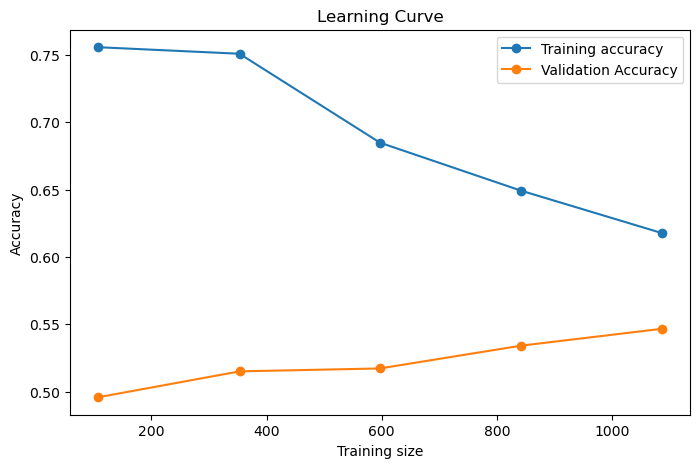

In [172]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(best_tree,X ,y ,cv = 5, scoring = 'accuracy')

plt.figure(figsize = (8,5))

plt.plot(train_sizes, train_scores.mean(axis = 1), marker = 'o', label = 'Training accuracy')
plt.plot(train_sizes, test_scores.mean(axis = 1), marker = 'o', label = 'Validation Accuracy')


plt.xlabel("Training size")
plt.ylabel("Accuracy")
plt.title("Learning Curve")

plt.legend()

plt.show()

In [173]:
# validation Curve


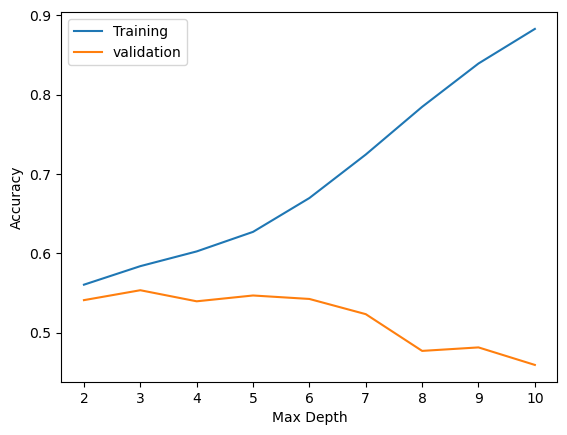

In [174]:
from sklearn.model_selection import validation_curve

param_range = [2,3,4,5,6,7,8,9,10]

train_score,test_score = validation_curve(DecisionTreeClassifier(criterion = 'entropy', random_state = 42), X,y, param_name = "max_depth", param_range=param_range,cv = 5)

plt.plot(param_range,train_score.mean(axis = 1),label= 'Training')

plt.plot(param_range, test_score.mean(axis = 1), label = 'validation')

plt.legend()

plt.xlabel("Max Depth")

plt.ylabel("Accuracy")

plt.show()